# DPWMS Module 2 — Plastic Characterisation at Dumpsites

**Programme requirement (concept note):**

> "apply more advanced AI and multispectral analysis to these identified sites
> to estimate the plastic concentration, distinguishing plastic-heavy hotspots
> from organic dumps"

Module 1 (`dumpsite_detection_workflow.ipynb`) finds *where* dumps are. This
module asks *what they are made of*. It is a harder problem on weaker evidence,
and this notebook is the record of testing whether it is achievable at all
before anything is promised as a deliverable.

---

### ⚠ Read this before the verdict: what is and is NOT being falsified

This notebook's negative result is **narrow**, and it is easy to read it as
much broader than it is. To be explicit:

**The DPWMS already detects floating-debris accumulation on water from
satellite imagery, and that layer is delivered**, with a benchmark on labelled
data (MARIDA) and a local photo review.

| already delivered | where | status |
|---|---|---|
| FDI **plastic accumulation patches** on water (FDI-and-NDVI rule, then MARIDA debris classifier) | `plasticwaste_analysis.ipynb`, `marida_workflow.ipynb` | 30 patches / 9.5 ha nationally, January 2024; monthly archive (GEDH-FR-0503, FR-0507) |
| Waste accumulation **sites** on land | `dumpsite_detection_workflow.ipynb` | nationwide dumpsite polygons (GEDH-FR-0503) |

GEDH-FR-0503 calls the marine layer *"FDI plastic accumulation patches"* in the
SRS's own words. **That requirement is met.**

What this notebook tests is the *second* sentence of the concept note's
Approach — estimating the **plastic fraction within an already-detected
dumpsite**, so as to rank plastic-heavy against organic dumps. That specific
quantity is what gates 2–4 falsify.

**The published terrestrial literature agrees.** The strongest satellite study
of land-based plastic waste (Wolf et al., *Satellite monitoring of terrestrial
plastic waste*, PLOS ONE / PMC9847976) uses Sentinel-2 to find waste **sites**,
reports a mean site area of 0.47 ha (~68 m across) and a minimum detectable
size of roughly 30 m — and states plainly that it **cannot determine plastic
fraction or concentration within a site; it identifies site presence only**.

So: site detection is the state of the art, and Module 1 already exceeds it for
Guinea by working at 0.3 m rather than 10 m — which matters, because Guinea's
dumps are ~14 m and would fall below that study's 30 m detection floor.

Nothing below contradicts the marine literature. It tests a different question
that the marine literature does not answer.

**This is a falsification notebook, not a demonstration.** Four gates were run,
each cheap and each capable of killing the approach. Three of the four came
back negative. That is the finding, and the honest deliverable is a scoped
retreat rather than a plastic map.

| gate | question | result |
|---|---|---|
| 1 | Does hyperspectral imagery of Guinea exist? | **open** — 110/111 dump points covered |
| 2 | Do Sentinel-2 plastic indices separate dumps? | **falsified** — they detect bare ground |
| 3 | Does the existing FDI code work on land? | **falsified** — same bare-ground proxy |
| 4 | Do EnMAP spectra show a plastic signature? | **falsified** — no C–H signal, 6 scenes |

Separately, dumpsite extent was measured for the first time (median **14 m**,
not the 50 m previously assumed), which explains gate 4.

All numbers below are recomputed from saved run outputs — nothing is typed in.

> **FDI definition.** The FDI follows Biermann et al. (2020, eq. 1–2): NIR = **B8**, RE2 = **B6**,
> SWIR1 = **B11**, with the **B4 (red)** wavelength in the interpolation ratio, pinned by
> `plasticwaste_tool/test_fdi_formula.py`. Gate 3 (FDI on land, §4) therefore samples B6 at every point;
> the gate-2 indices do not use B6. The gate-3 cell runs the sample extraction and the FDI evaluation in
> that order:
>
> ```
> python -m plasticwaste_tool.characterisation_tool.s2_indices
> python -m plasticwaste_tool.characterisation_tool.fdi_on_land
> ```

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd()
if not (ROOT / "plasticwaste_tool").exists():
    ROOT = ROOT.parent
PW   = ROOT / "plasticwaste_tool"
RUNS = PW / "runs"
FIGS = RUNS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PW))

# This machine's system PROJ_LIB points at PostgreSQL/PostGIS, which shadows
# rasterio's bundled proj.db and breaks every CRS operation — including the
# basemaps below. Repoint it for this process only; see plasticwaste_tool/geo_env.py
from geo_env import fix_proj
fix_proj(verbose=True)

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
INK, WARN, BAD, MUTE = "#1f6fb4", "#e08a1e", "#c0392b", "#8a9099"

def save(fig, name):
    p = FIGS / f"{name}.png"
    fig.savefig(p)
    print("wrote", p.relative_to(ROOT))

print("root:", ROOT)

PROJ_LIB: C:\Program Files\PostgreSQL\13\share\contrib\postgis-3.2\proj -> c:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\site-packages\rasterio\proj_data
root: c:\Users\ASUS\Guinea_Project\Land Use-Deforestation


## 1. The physical constraint that governs everything

Plastic identification from orbit rests on **C–H bond absorption in the
shortwave infrared**, near **1215 nm** and **1730 nm**. That is the only
physically grounded signal. Everything else is an appearance proxy.

This matters more than it first appears, because of a fact that is easy to get
backwards: **Sentinel-2 has SWIR bands, but neither diagnostic feature falls
inside one.** Both sit in gaps between its bands.

The consequence is that PMLI, PGI and the rest of the plastic-mulch index
family do **not** measure C–H absorption. They measure the broad shape of the
SWIR continuum, which large uniform plastic sheeting happens to alter. Against
heterogeneous mixed waste that is a much weaker claim — and gate 2 tests it.

wrote plasticwaste_tool\runs\figures\01_band_coverage.png


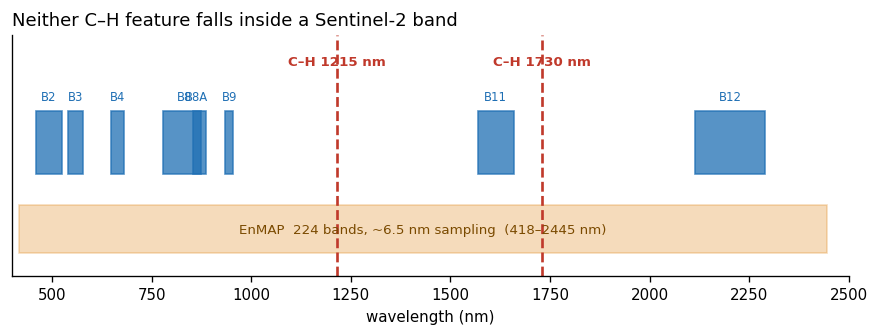

1215 nm -> S2 band containing it: NONE   gap 945->1614 nm (669 nm wide)
1730 nm -> S2 band containing it: NONE   gap 1614->2202 nm (588 nm wide)


In [2]:
S2 = {"B2":(492,66),"B3":(559,36),"B4":(665,31),"B8":(833,106),
      "B8A":(864,21),"B9":(945,20),"B11":(1614,91),"B12":(2202,175)}
CH = (1215, 1730)

fig, ax = plt.subplots(figsize=(9, 2.6))
for name,(c,w) in S2.items():
    ax.add_patch(plt.Rectangle((c-w/2, .55), w, .34, color=INK, alpha=.75))
    ax.text(c, .95, name, ha="center", fontsize=7, color=INK)
ax.add_patch(plt.Rectangle((418, .12), 2445-418, .26, color=WARN, alpha=.30))
ax.text(1430, .25, "EnMAP  224 bands, ~6.5 nm sampling  (418–2445 nm)",
        ha="center", va="center", fontsize=8, color="#7a4a00")
for f in CH:
    ax.axvline(f, color=BAD, lw=1.6, ls="--")
    ax.text(f, 1.14, f"C–H {f} nm", ha="center", color=BAD, fontsize=8, fontweight="bold")
ax.set_xlim(400, 2500); ax.set_ylim(0, 1.3)
ax.set_yticks([]); ax.set_xlabel("wavelength (nm)")
ax.set_title("Neither C–H feature falls inside a Sentinel-2 band", loc="left")
ax.grid(False)
save(fig, "01_band_coverage"); plt.show()

for f in CH:
    inside = [b for b,(c,w) in S2.items() if c-w/2 <= f <= c+w/2]
    below = max(c for c,_ in S2.values() if c < f)
    above = min(c for c,_ in S2.values() if c > f)
    print(f"{f} nm -> S2 band containing it: {inside or 'NONE'}"
          f"   gap {below}->{above} nm ({above-below} nm wide)")

## 1b. Where the sites are

Before the gates, the spatial picture. **Note what is NOT on this map: plastic
content.** There is no plastic-heaviness value for any site — establishing that
it cannot be measured is the result of this notebook (§6–7). What *is* mappable
is where the dumps are, how big they are, and which sit on water.

Three maps below: the national sample, the measured size distribution in space,
and the waterside flag that §8 proposes shipping.

In [3]:
import geopandas as gpd
from shapely.geometry import Point

lab = json.loads((PW / "manual_qa" / "regions" / "national_random_sample.geojson").read_text())
recs = []
for f in lab["features"]:
    p = f["properties"]
    if str(p.get("label")) == "1" and p.get("lat"):
        las = [s for s in str(p["lat"]).split(";") if s.strip()]
        los = [s for s in str(p["long"]).split(";") if s.strip()]
        for i, (la, lo) in enumerate(zip(las, los)):
            recs.append(dict(point_id=f"{p['tile_id']}_p{i}", tile_id=p["tile_id"],
                             region=p["region"], label=1,
                             lon=float(lo), lat=float(la)))
    elif str(p.get("label")) == "0":
        c = f["geometry"]["coordinates"][0]
        recs.append(dict(point_id=p["tile_id"], tile_id=p["tile_id"],
                         region=p["region"], label=0,
                         lon=float(np.mean([x[0] for x in c])),
                         lat=float(np.mean([x[1] for x in c]))))

pts = gpd.GeoDataFrame(pd.DataFrame(recs),
                       geometry=[Point(r["lon"], r["lat"]) for r in recs], crs="EPSG:4326")

# attach measured extent (one row per cell -> broadcast to that cell's p0)
ext_all = pd.read_csv(RUNS / "dumpsite_extent" / "extent_annotated_usable.csv")
pts = pts.merge(ext_all[["point_id", "area_equiv_m"]], on="point_id", how="left")

# attach WorldCover class
wc = pd.read_csv(RUNS / "fdi_on_land" / "worldcover_at_dumps.csv")
pts = pts.merge(wc[["point_id", "worldcover"]], on="point_id", how="left")
pts["waterside"] = pts["worldcover"].isin([80, 90, 95])

print(f"{(pts.label==1).sum()} dump points, {(pts.label==0).sum()} negatives")
print(f"{pts['area_equiv_m'].notna().sum()} with a measured extent, "
      f"{int(pts['waterside'].sum())} on water/wetland/mangrove")

111 dump points, 540 negatives
46 with a measured extent, 19 on water/wetland/mangrove


wrote plasticwaste_tool\runs\figures\07_map_national_sample.png


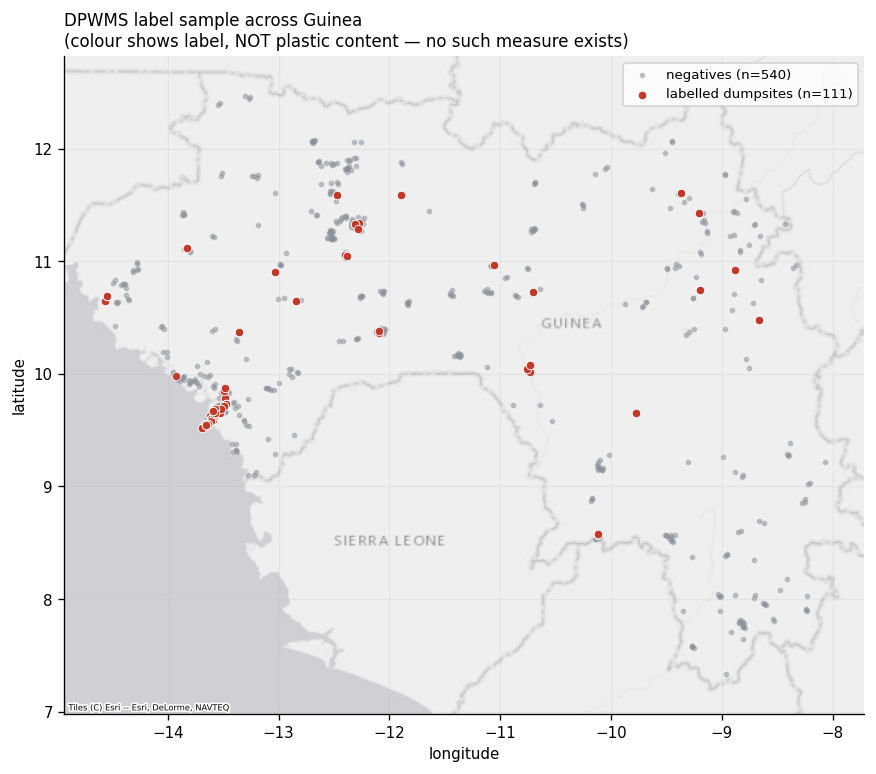

In [4]:
import contextily as cx

def basemap(ax, gdf, pad=0.35):
    minx, miny, maxx, maxy = gdf.total_bounds
    ax.set_xlim(minx-pad, maxx+pad); ax.set_ylim(miny-pad, maxy+pad)
    # Provider choice is not cosmetic: OpenStreetMap 403-blocks non-browser
    # tile fetching ("not following the tile usage policy"), and CartoDB's free
    # tier stamps "API KEY REQUIRED" diagonally across every tile. Esri serves
    # both fine.
    for src in (cx.providers.Esri.WorldGrayCanvas, cx.providers.Esri.WorldTopoMap):
        try:
            cx.add_basemap(ax, crs="EPSG:4326", source=src, attribution_size=5)
            break
        except Exception as e:
            print(f"!! basemap {src.get('name','?')} failed: {type(e).__name__}: {e}")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.grid(alpha=.15)

dumps = pts[pts.label == 1]
negs  = pts[pts.label == 0]

fig, ax = plt.subplots(figsize=(8.6, 7.2))
negs.plot(ax=ax, color=MUTE, markersize=6, alpha=.45, label=f"negatives (n={len(negs)})")
dumps.plot(ax=ax, color=BAD, markersize=26, edgecolor="white", linewidth=.5,
           label=f"labelled dumpsites (n={len(dumps)})")
basemap(ax, pts)
ax.legend(frameon=True, fontsize=8, loc="upper right")
ax.set_title("DPWMS label sample across Guinea\n"
             "(colour shows label, NOT plastic content — no such measure exists)",
             loc="left", fontsize=10)
save(fig, "07_map_national_sample"); plt.show()

wrote plasticwaste_tool\runs\figures\08_map_size_class.png


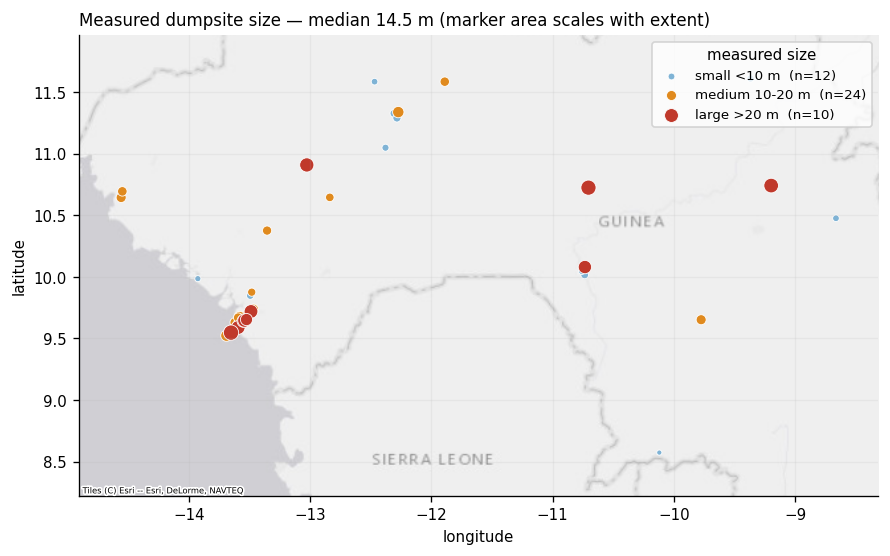

,n,median_m
size_class,,
small <10 m,12,7.0
medium 10-20 m,24,15.0
large >20 m,10,28.5


In [5]:
m = dumps[dumps.area_equiv_m.notna()].copy()
bins = [0, 10, 20, 100]
names = ["small <10 m", "medium 10-20 m", "large >20 m"]
m["size_class"] = pd.cut(m.area_equiv_m, bins=bins, labels=names)
cols = {"small <10 m": "#7fb3d5", "medium 10-20 m": WARN, "large >20 m": BAD}

fig, ax = plt.subplots(figsize=(8.6, 7.2))
for name in names:
    s = m[m.size_class == name]
    if s.empty: continue
    s.plot(ax=ax, color=cols[name], markersize=s.area_equiv_m*2.4,
           edgecolor="white", linewidth=.5, label=f"{name}  (n={len(s)})")
basemap(ax, dumps)
ax.legend(frameon=True, fontsize=8, loc="upper right", title="measured size")
ax.set_title(f"Measured dumpsite size — median {m.area_equiv_m.median():.1f} m "
             f"(marker area scales with extent)", loc="left", fontsize=10)
save(fig, "08_map_size_class"); plt.show()

display(m.groupby("size_class", observed=True)
         .agg(n=("area_equiv_m", "size"), median_m=("area_equiv_m", "median")).round(1))

wrote plasticwaste_tool\runs\figures\09_map_waterside.png


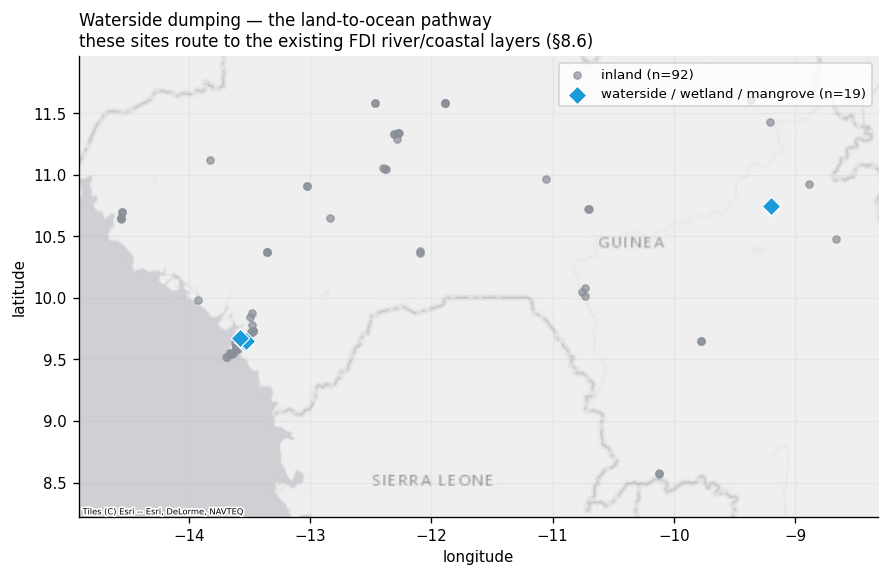

WorldCover class at dump points:
worldcover
built-up           46
grassland          17
permanent water    13
tree cover         10
cropland           10
shrubland           5
bare/sparse         4
mangroves           3
herb. wetland       3

waterside points: 19 across 5 distinct cells (point counts overstate it — one Kankan cell holds many)


In [6]:
WC = {10:"tree cover",20:"shrubland",30:"grassland",40:"cropland",50:"built-up",
      60:"bare/sparse",80:"permanent water",90:"herb. wetland",95:"mangroves"}

fig, ax = plt.subplots(figsize=(8.6, 7.2))
land = dumps[~dumps.waterside]
water = dumps[dumps.waterside]
land.plot(ax=ax, color=MUTE, markersize=18, alpha=.7,
          label=f"inland (n={len(land)})")
water.plot(ax=ax, color="#1a9bd7", markersize=60, marker="D",
           edgecolor="white", linewidth=.6,
           label=f"waterside / wetland / mangrove (n={len(water)})")
basemap(ax, dumps)
ax.legend(frameon=True, fontsize=8, loc="upper right")
ax.set_title("Waterside dumping — the land-to-ocean pathway\n"
             "these sites route to the existing FDI river/coastal layers (§8.6)",
             loc="left", fontsize=10)
save(fig, "09_map_waterside"); plt.show()

print("WorldCover class at dump points:")
print(dumps["worldcover"].map(WC).value_counts().to_string())
print(f"\nwaterside points: {len(water)} across "
      f"{water.tile_id.nunique()} distinct cells "
      f"(point counts overstate it — one Kankan cell holds many)")

## 2. Gate 1 — is there any hyperspectral imagery of Guinea?

PRISMA, EnMAP and EMIT are *tasked* missions, not global-daily like Sentinel-2.
They image where someone asked them to, and Guinea is not an agricultural or
mineral-exploration priority. If the archive is empty this path closes for free.

It is not empty. **Coverage is far better than expected, and the two usable
missions are near-complementary**: EnMAP covers Conakry completely where EMIT
is weak, EMIT covers Boké entirely where EnMAP has nothing.

Reproduce with `plasticwaste_tool/10_hyperspectral_coverage.py`.

,range_nm,GSD_m,bands,sees_CH,scenes_over_Guinea,scenes_on_a_dump,dumps_<20%_cloud
mission,,,,,,,
EMIT,381–2493,60,285,yes,1111,214,75
EnMAP,420–2450,30,224,yes,540,27,93
DESIS,400–1000,30,235,NO,0,0,0


wrote plasticwaste_tool\runs\figures\02_coverage_by_region.png


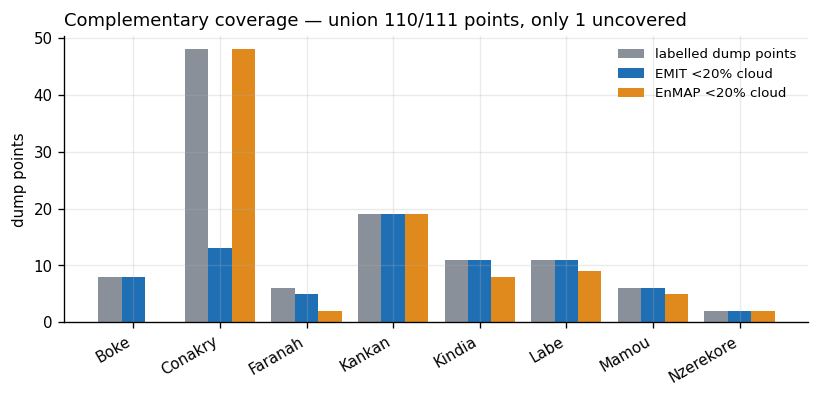

In [7]:
cov = json.loads((RUNS / "hyperspectral_coverage" / "coverage_summary.json").read_text())
comp = cov["complementarity"]

rows = []
for m in ("EMIT", "EnMAP", "DESIS"):
    r = cov["missions"][m]; spec = cov["sensor_specs"][m]
    u = r.get("dump_point_usability", {})
    rows.append({"mission": m, "range_nm": f"{spec['min_nm']}–{spec['max_nm']}",
                 "GSD_m": spec["gsd_m"], "bands": spec["n_bands"],
                 "sees_CH": "yes" if spec["covers_ch_1730nm"] else "NO",
                 "scenes_over_Guinea": r.get("bbox_hits"),
                 "scenes_on_a_dump": r.get("items_containing_a_dump_point"),
                 "dumps_<20%_cloud": u.get("points_with_a_scene_lt20pct_cloud")})
display(pd.DataFrame(rows).set_index("mission"))

regs = list(comp["region_totals"])
tot  = [comp["region_totals"][r] for r in regs]
emit = [comp["emit_by_region"].get(r, 0) for r in regs]
enm  = [comp["enmap_by_region"].get(r, 0) for r in regs]
x = np.arange(len(regs)); w = .27

fig, ax = plt.subplots(figsize=(8, 3.1))
ax.bar(x-w, tot,  w, label="labelled dump points", color=MUTE)
ax.bar(x,   emit, w, label="EMIT <20% cloud",  color=INK)
ax.bar(x+w, enm,  w, label="EnMAP <20% cloud", color=WARN)
ax.set_xticks(x); ax.set_xticklabels(regs, rotation=30, ha="right")
ax.set_ylabel("dump points"); ax.legend(frameon=False, fontsize=8)
ax.set_title(f"Complementary coverage — union {comp['union']}/{comp['n_points_total']} "
             f"points, only {comp['uncovered']} uncovered", loc="left")
save(fig, "02_coverage_by_region"); plt.show()

wrote plasticwaste_tool\runs\figures\10_map_enmap_footprints.png


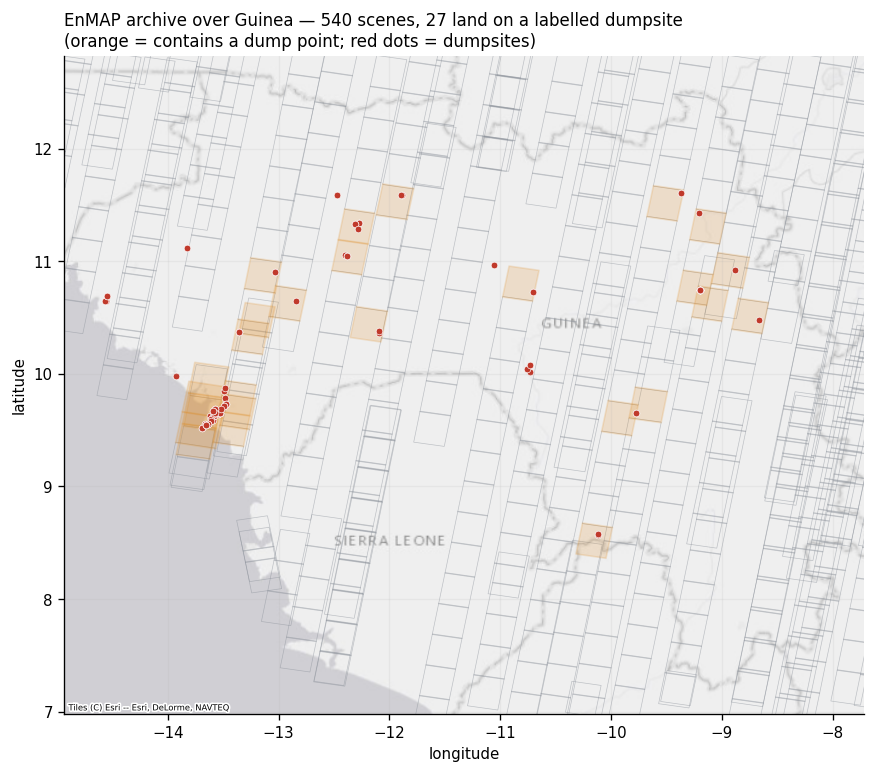

In [8]:
# Where the EnMAP scenes actually fall — footprints from the STAC records.
from shapely.geometry import shape

items = json.loads((RUNS / "hyperspectral_coverage" / "enmap_items.json").read_text())
on_dump = {i["id"] for i in cov["missions"]["EnMAP"]["items"]}

geoms, used = [], []
for it in items:
    if not it.get("geometry"): continue
    geoms.append(shape(it["geometry"]))
    used.append(it["id"] in on_dump)
foot = gpd.GeoDataFrame({"on_dump": used}, geometry=geoms, crs="EPSG:4326")

fig, ax = plt.subplots(figsize=(8.6, 7.2))
foot[~foot.on_dump].plot(ax=ax, facecolor="none", edgecolor=MUTE, lw=.4, alpha=.5)
foot[foot.on_dump].plot(ax=ax, facecolor=WARN, alpha=.18, edgecolor=WARN, lw=1.0)
dumps.plot(ax=ax, color=BAD, markersize=16, edgecolor="white", linewidth=.4)
basemap(ax, pts)
ax.set_title(f"EnMAP archive over Guinea — {len(foot)} scenes, "
             f"{int(foot.on_dump.sum())} land on a labelled dumpsite\n"
             "(orange = contains a dump point; red dots = dumpsites)",
             loc="left", fontsize=10)
save(fig, "10_map_enmap_footprints"); plt.show()

## 3. Gate 2 — do Sentinel-2 plastic indices separate dumps from non-dumps?

If published plastic indices cannot even separate 111 known dump points from
540 known negatives, they will not rank plastic *within* dumps.

Ten indices were computed from a dry-season median composite, every formula
transcribed from a published source (Lu/Di/Ye 2014; Yang et al. 2017; Hasituya
et al. 2019; band mapping per Gungor et al. 2026). **NDVI and NDBI are included
as controls — they have no plastic sensitivity whatsoever.**

Average precision is used rather than ROC-AUC because prevalence is 17%
(Saito & Rehmsmeier 2015); confidence intervals come from a cluster bootstrap
that resamples whole label cells, since one cell can hold several dump points.

wrote plasticwaste_tool\runs\figures\03_s2_index_ap.png


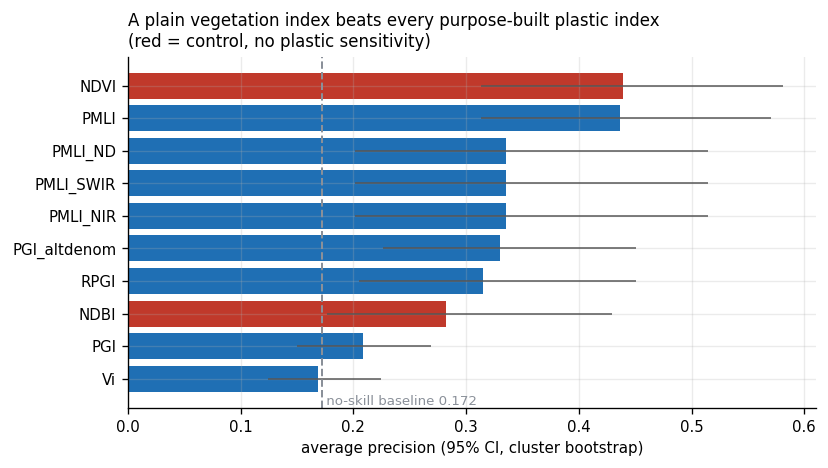

Paired bootstrap — the comparison that matters:
  NDVI_minus_PMLI                    dAP=+0.000 [-0.089,+0.081]  not significant
  NDVI_minus_PMLI_NIR                dAP=+0.105 [-0.006,+0.204]  not significant
  NDVI_minus_PMLI_SWIR               dAP=+0.105 [-0.006,+0.204]  not significant
  NDVI_minus_PMLI_ND                 dAP=+0.105 [-0.006,+0.204]  not significant
  NDVI_minus_PGI_altdenom            dAP=+0.108 [-0.004,+0.219]  not significant
  NDVI_minus_RPGI                    dAP=+0.124 [+0.050,+0.207]  SIGNIFICANT
  NDVI_minus_NDBI                    dAP=+0.156 [+0.062,+0.251]  SIGNIFICANT
  NDVI_minus_PGI                     dAP=+0.235 [+0.149,+0.331]  SIGNIFICANT
  NDVI_minus_Vi                      dAP=+0.271 [+0.171,+0.378]  SIGNIFICANT
  NDVI_minus_baseline                dAP=+0.270 [+0.142,+0.410]  SIGNIFICANT


In [9]:
ev = json.loads((RUNS / "s2_plastic_indices" / "evaluation.json").read_text())
fp = ev["footprints"]["native_pixel"]
base = fp["prevalence"]

idx = pd.DataFrame([
    {"index": k, "AP": v["ap"], "lo": v["ci95"][0], "hi": v["ci95"][1],
     "lift": v["lift_over_baseline"]}
    for k, v in fp["indices"].items()]).sort_values("AP")

fig, ax = plt.subplots(figsize=(7.4, 3.8))
colors = [BAD if i in ("NDVI", "NDBI") else INK for i in idx["index"]]
ax.barh(idx["index"], idx["AP"], color=colors,
        xerr=[idx.AP-idx.lo, idx.hi-idx.AP], error_kw=dict(lw=.9, ecolor="#555"))
ax.axvline(base, color=MUTE, ls="--", lw=1.2)
ax.text(base, -.8, f" no-skill baseline {base:.3f}", color=MUTE, fontsize=8)
ax.set_xlabel("average precision (95% CI, cluster bootstrap)")
ax.set_title("A plain vegetation index beats every purpose-built plastic index\n"
             "(red = control, no plastic sensitivity)", loc="left", fontsize=10)
save(fig, "03_s2_index_ap"); plt.show()

print("Paired bootstrap — the comparison that matters:")
for k, v in fp["paired_comparisons"].items():
    flag = "SIGNIFICANT" if v["excludes_zero"] else "not significant"
    print(f"  {k:<34} dAP={v['delta_ap']:+.3f} "
          f"[{v['ci95'][0]:+.3f},{v['ci95'][1]:+.3f}]  {flag}")

### The decisive sub-test: do the plastic indices add anything over NDVI?

Two spatially-blocked models on identical folds — NDVI alone, versus NDVI plus
every plastic index. If the plastic indices carried plastic-specific
information, the second would win.

In [10]:
rows = []
for name, f in ev["footprints"].items():
    iv = f.get("incremental_value")
    if not iv: continue
    d = iv["paired_comparisons"]["NDVI_plus_plastic_minus_NDVI_only"]
    rows.append({"footprint": name, "NDVI only": iv["oof_ap"]["NDVI_only"],
                 "plastic only": iv["oof_ap"]["plastic_indices_only"],
                 "NDVI+plastic": iv["oof_ap"]["NDVI_plus_plastic"],
                 "delta": d["delta_ap"],
                 "95% CI": f"[{d['ci95'][0]:+.3f}, {d['ci95'][1]:+.3f}]",
                 "significant": d["excludes_zero"]})
inc = pd.DataFrame(rows).set_index("footprint")
display(inc.round(3))
print("\nAt the dump's own scale (native 20 m pixel) the plastic indices add nothing.")
print("The only footprint where they help is 250 m — the footprint Module 1 already")
print("established measures the NEIGHBOURHOOD rather than the dump.")

,NDVI only,plastic only,NDVI+plastic,delta,95% CI,significant
footprint,,,,,,
250m_box,0.446,0.530,0.529,0.083,"[+0.010, +0.160]",True
80m_box,0.445,0.503,0.503,0.060,"[-0.037, +0.161]",False
native_pixel,0.466,0.457,0.457,-0.003,"[-0.090, +0.082]",False



At the dump's own scale (native 20 m pixel) the plastic indices add nothing.
The only footprint where they help is 250 m — the footprint Module 1 already
established measures the NEIGHBOURHOOD rather than the dump.


## 4. Gate 3 — does the existing FDI code respond on land?

Guinea's floating-debris detector is built for water. The question is whether
its FDI code says anything useful over a terrestrial dumpsite. It is imported
unmodified from `plasticwaste_tool/spectral.py`.

FDI does respond, but as another vegetation measure. With the index as Biermann
et al. (2020) define it, the rise from the red-edge band (B6) to the
near-infrared (B8) is a vegetation signal, so dumpsites — bare, disturbed
ground — read *lower* FDI than their vegetated surroundings. That is the same
non-specific signal NDVI carries, and the cell below shows FDI carrying it less
well than NDVI at every footprint. It is also why the marine pipeline requires
a positive water constraint: over land the index responds to surface cover, not
to floating material.

In [11]:
# Re-run gate 3 under the corrected FDI (B6 = Biermann et al.'s RE2 band).
# 1. Re-extract the Sentinel-2 sample values: the CSV now carries B6.
#    Earth Engine, a few minutes. The gate-2 indices do not use B6, so the
#    gate-2 numbers above should not move.
# 2. Re-score FDI on land with the corrected index.
import subprocess
for module in ("plasticwaste_tool.characterisation_tool.s2_indices",
               "plasticwaste_tool.characterisation_tool.fdi_on_land"):
    print("$ python -m", module, flush=True)
    p = subprocess.run([sys.executable, "-m", module], cwd=ROOT,
                       capture_output=True, text=True)
    print(p.stdout[-4000:])
    if p.returncode != 0:
        print("STDERR:", p.stderr[-3000:])
        raise RuntimeError(f"{module} failed; see STDERR above")

$ python -m plasticwaste_tool.characterisation_tool.s2_indices
Sentinel-2 terrestrial plastic indices at labelled dumpsites
  GEE initialised via landuse_tool.api_connector: True (key: tribal-mapper-275801-7b57ce84f3bd.json)

Points: 651  (111 positive dump points, 540 negative cell centroids)
Dry-season composite: 7260 scenes (months [12, 1, 2, 3], 2023-2025, SCL clear-land classes [4, 5, 7])

  extracting footprint: native_pixel
    150/651
    300/651
    450/651
    600/651
    651/651

  extracting footprint: 80m_box
    150/651
    300/651
    450/651
    600/651
    651/651

  extracting footprint: 250m_box
    150/651
    300/651
    450/651
    600/651
    651/651

Wrote 1953 rows to C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\plasticwaste_tool\runs\s2_plastic_indices\s2_index_samples.csv

Non-null band coverage by footprint:
  250m_box       651/651 points have B11 (111 of 111 positives)
  80m_box        648/651 points have B11 (111 of 111 positives)
  native_pixel   

In [12]:
fdi = json.loads((RUNS / "fdi_on_land" / "fdi_land_evaluation.json").read_text())

rows = []
for name, f in fdi["footprints"].items():
    s = f["scores"]
    rows.append({"footprint": name, "baseline": f["baseline"],
                 "FDI": s["FDI"]["ap"], "NDVI": s["NDVI"]["ap"], "PMLI": s["PMLI"]["ap"],
                 "FDI-NDVI": f["comparisons"]["FDI_minus_NDVI"]["delta_ap"],
                 "sig": f["comparisons"]["FDI_minus_NDVI"]["excludes_zero"]})
display(pd.DataFrame(rows).set_index("footprint").round(3))

pm = fdi["pipeline_masks"]
print("\nThe FDI PIPELINE, with its real masks, on land:")
for name, m in pm.items():
    print(f"  {name:<14} NDVI/NDWI only: {m['survive_ndvi_ndwi_only']:>3}/{m['n_points']} survive"
          f"   + WATER constraint: {m['survive_with_water_constraint']}/{m['n_points']}")
print("\n-> zero land pixels survive. The pipeline is correctly scoped to water.")

wc = fdi["worldcover_at_dumps"]
print(f"\nESA WorldCover at the {wc['n_points']} dump points:")
names = {"10":"tree cover","20":"shrubland","30":"grassland","40":"cropland",
         "50":"built-up","60":"bare/sparse","80":"permanent water",
         "90":"herb. wetland","95":"mangroves"}
for k, v in sorted(wc["class_counts"].items(), key=lambda x: -x[1]):
    print(f"   {names.get(k,k):<18} {v}")

,baseline,FDI,NDVI,PMLI,FDI-NDVI,sig
footprint,,,,,,
250m_box,0.171,0.238,0.447,0.476,-0.206,True
80m_box,0.171,0.282,0.437,0.460,-0.155,True
native_pixel,0.172,0.301,0.440,0.436,-0.147,True



The FDI PIPELINE, with its real masks, on land:
  250m_box       NDVI/NDWI only:  47/651 survive   + WATER constraint: 0/651
  80m_box        NDVI/NDWI only:  68/648 survive   + WATER constraint: 0/648
  native_pixel   NDVI/NDWI only:  87/646 survive   + WATER constraint: 0/646

-> zero land pixels survive. The pipeline is correctly scoped to water.

ESA WorldCover at the 111 dump points:
   built-up           46
   grassland          17
   permanent water    13
   tree cover         10
   cropland           10
   shrubland          5
   bare/sparse        4
   mangroves          3
   herb. wetland      3


## 5. How big is a Guinean dumpsite? (measured, finally)

Every pixel-count argument until now rested on an **assumed** 50 m site,
because Guinea dumpsite extents had never been digitised — the labels are 250 m
cells plus a point, not polygons.

An automated attempt (`14_dumpsite_extent.py`) failed its own control: the
encircled-excess estimators scored non-dumps *larger* than dumps, because with
no central peak their "excess" is background noise spread over the frame. So
54 of 55 positive cells were annotated by hand
(`16_build_extent_annotator.py`).

**The answer is ~14 m, not 50 m** — and it reframes everything that follows.

wrote plasticwaste_tool\runs\figures\04_extent_and_pixels.png


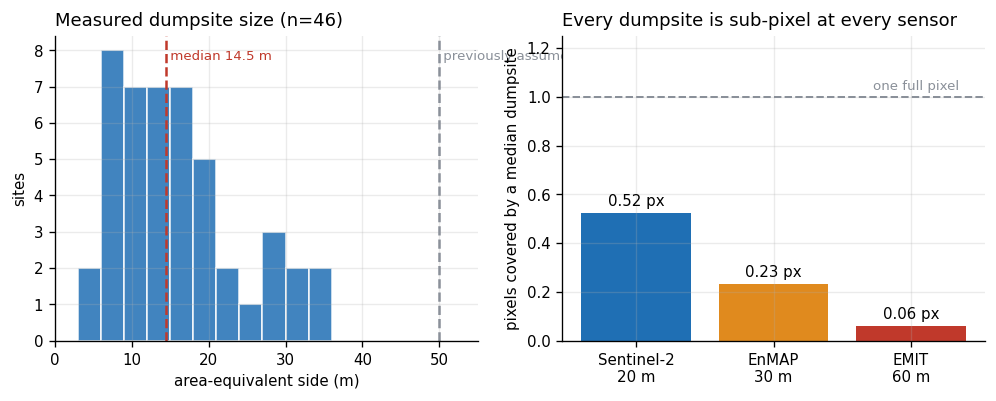

p25 9.9 m   median 14.5 m   p75 19.5 m   max 35.0 m
sites flagged 'extends beyond the 80 m frame': 0 -> no censoring, the crop was ample
  Sentinel-2   sites reaching a full pixel: 22%
  EnMAP        sites reaching a full pixel: 9%
  EMIT         sites reaching a full pixel: 0%


In [13]:
ext = pd.read_csv(RUNS / "dumpsite_extent" / "extent_annotated_usable.csv")
summ = json.loads((RUNS / "dumpsite_extent" / "extent_annotated_summary.json").read_text())
a = ext["area_equiv_m"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))

ax1.hist(a, bins=np.arange(0, 42, 3), color=INK, alpha=.85, edgecolor="white")
for v, lab, col in ((a.median(), f"median {a.median():.1f} m", BAD),
                    (50, "previously assumed 50 m", MUTE)):
    ax1.axvline(v, color=col, ls="--", lw=1.5)
    ax1.text(v, ax1.get_ylim()[1]*.92, " "+lab, color=col, fontsize=8)
ax1.set_xlim(0, 55)
ax1.set_xlabel("area-equivalent side (m)"); ax1.set_ylabel("sites")
ax1.set_title(f"Measured dumpsite size (n={len(a)})", loc="left")

sensors = [("Sentinel-2\n20 m", 20), ("EnMAP\n30 m", 30), ("EMIT\n60 m", 60)]
fill = [ (a.median()**2)/(g**2) for _, g in sensors ]
bars = ax2.bar([s for s,_ in sensors], fill, color=[INK, WARN, BAD])
ax2.axhline(1.0, color=MUTE, ls="--", lw=1.2)
ax2.text(2.35, 1.03, "one full pixel", color=MUTE, fontsize=8, ha="right")
for b, f in zip(bars, fill):
    ax2.text(b.get_x()+b.get_width()/2, f+.03, f"{f:.2f} px", ha="center", fontsize=9)
ax2.set_ylim(0, 1.25); ax2.set_ylabel("pixels covered by a median dumpsite")
ax2.set_title("Every dumpsite is sub-pixel at every sensor", loc="left")
save(fig, "04_extent_and_pixels"); plt.show()

print(f"p25 {a.quantile(.25):.1f} m   median {a.median():.1f} m   "
      f"p75 {a.quantile(.75):.1f} m   max {a.max():.1f} m")
print(f"sites flagged 'extends beyond the 80 m frame': {int(ext.beyond_frame.sum())} "
      f"-> no censoring, the crop was ample")
for name, g in sensors:
    print(f"  {name.split(chr(10))[0]:<12} sites reaching a full pixel: "
          f"{100*(a>=g).mean():.0f}%")

## 5b. How reproducible is that extent measurement?

The size distribution above came from one interpreter. Before it can carry the
pixel-count argument, it needs an agreement estimate — otherwise "14 m" is a
number with no stated precision.

A random subsample of 12 sites (fixed seed, **not** stratified by size, which
would condition the sample on the values under test) was measured a second
time, **blind**: the second reader saw the crops with a metric grid and never
saw the first-pass values until both were recorded.

**What this is:** a *reproducibility* estimate — how stable is the judgement
when the same imagery is measured again independently. The second read was
performed by the AI assistant, not a second human analyst, so it is **not** a
human inter-rater agreement figure. A model reader and a human reader may share
or differ in biases in ways two humans would not.

wrote plasticwaste_tool\runs\figures\12_extent_agreement.png


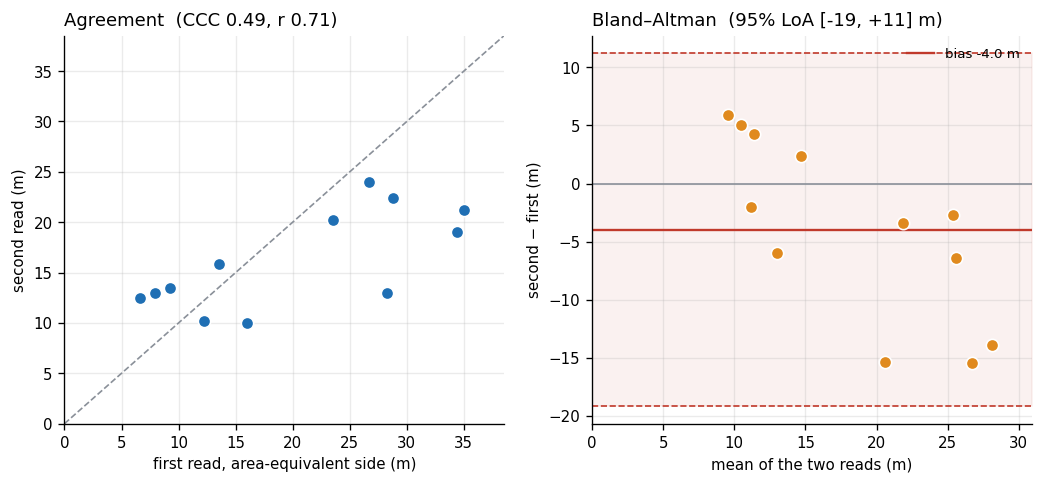

n = 12 sites
  mean absolute difference  6.9 m
  median relative difference 42%
  Lin's concordance (CCC)   0.485   (>0.90 would be good)


In [14]:
ag = json.loads((RUNS / "dumpsite_extent" / "extent_agreement.json").read_text())
pairs = pd.read_csv(RUNS / "dumpsite_extent" / "extent_agreement_pairs.csv")

a = pairs["area_equiv_m_first"].to_numpy()
b = pairs["area_equiv_m_second"].to_numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.4, 4.2))

lim = max(a.max(), b.max()) * 1.1
ax1.plot([0, lim], [0, lim], color=MUTE, ls="--", lw=1)
ax1.scatter(a, b, s=55, color=INK, edgecolor="white", zorder=3)
ax1.set_xlim(0, lim); ax1.set_ylim(0, lim)
ax1.set_xlabel("first read, area-equivalent side (m)")
ax1.set_ylabel("second read (m)")
ax1.set_title(f"Agreement  (CCC {ag['ccc']:.2f}, r {ag['pearson_r']:.2f})",
              loc="left")

mean_ab = (a + b) / 2
diff = b - a
ax2.axhline(0, color=MUTE, lw=1)
ax2.axhline(ag["bias_m"], color=BAD, lw=1.4, label=f"bias {ag['bias_m']:+.1f} m")
for L in ag["loa95_m"]:
    ax2.axhline(L, color=BAD, ls="--", lw=1)
ax2.fill_between([0, mean_ab.max()*1.1], ag["loa95_m"][0], ag["loa95_m"][1],
                 color=BAD, alpha=.07)
ax2.scatter(mean_ab, diff, s=55, color=WARN, edgecolor="white", zorder=3)
ax2.set_xlim(0, mean_ab.max()*1.1)
ax2.set_xlabel("mean of the two reads (m)")
ax2.set_ylabel("second − first (m)")
ax2.set_title(f"Bland–Altman  (95% LoA "
              f"[{ag['loa95_m'][0]:+.0f}, {ag['loa95_m'][1]:+.0f}] m)", loc="left")
ax2.legend(frameon=False, fontsize=8)
save(fig, "12_extent_agreement"); plt.show()

print(f"n = {ag['n']} sites")
print(f"  mean absolute difference  {ag['mean_abs_diff_m']:.1f} m")
print(f"  median relative difference {ag['median_rel_diff']*100:.0f}%")
print(f"  Lin's concordance (CCC)   {ag['ccc']:.3f}   (>0.90 would be good)")

### The agreement is poor — and the conclusion survives it anyway

Per-site agreement is **weak**: 42% median relative difference, limits of
agreement spanning roughly ±15 m, concordance 0.49. The two reads *rank* sites
similarly (r = 0.71) but disagree substantially on absolute size.

That is not sloppiness, and the site notes show why. The largest disagreements
are **definitional, not metric** — at `nat_cona_0051` the second reader measured
only the central cluster while the first included a further scatter to the east;
at `nat_fara_0025` the contrast is so low that the boundary is a judgement call.
**A diffuse debris scatter has no crisp edge**, which is the same ambiguity that
defeated the automated estimator in §5.

So the honest statement is: **the absolute size figure is not quotable to
better than about 40%.** The question is whether that reaches the decision it
feeds.

In [15]:
print("Decision: is a median dumpsite resolvable by a 30 m EnMAP pixel?\n")
rows = []
for lbl, key, med in (("first read", "median_first_ci", ag["median_first_m"]),
                      ("second read", "median_second_ci", ag["median_second_m"])):
    lo, hi = ag[key]
    rows.append({"read": lbl, "median (m)": round(med, 1),
                 "95% CI (m)": f"[{lo:.1f}, {hi:.1f}]",
                 "EnMAP px": round(med**2 / 900, 2),
                 "EnMAP px at upper CI": round(hi**2 / 900, 2),
                 "P(median >= 30 m)": f"{ag['p_median_ge_30m'][lbl.split()[0]]:.1%}"})
display(pd.DataFrame(rows).set_index("read"))

d = ag["median_diff"]; dci = ag["median_diff_ci"]
print(f"difference of medians {d:+.1f} m  [{dci[0]:+.1f}, {dci[1]:+.1f}] "
      f"-- the two medians are not significantly different\n")
print("A dumpsite needs to reach 30 m to fill one EnMAP pixel. Under BOTH reads")
print("the probability that the median site does so is under 1%, and even the")
print("upper confidence bound of the larger read stays below one full pixel.")
print("\nThe measurement is imprecise. The conclusion it supports is not")
print("sensitive to that imprecision.")

Decision: is a median dumpsite resolvable by a 30 m EnMAP pixel?



,median (m),95% CI (m),EnMAP px,EnMAP px at upper CI,P(median >= 30 m)
read,,,,,
first read,19.8,"[10.7, 28.5]",0.43,0.90,0.5%
second read,14.7,"[12.7, 20.7]",0.24,0.48,0.0%


difference of medians -4.4 m  [-13.5, +2.4] -- the two medians are not significantly different

A dumpsite needs to reach 30 m to fill one EnMAP pixel. Under BOTH reads
the probability that the median site does so is under 1%, and even the
upper confidence bound of the larger read stays below one full pixel.

The measurement is imprecise. The conclusion it supports is not
sensitive to that imprecision.


## 6. Gate 4 — the decisive test: do EnMAP spectra show a plastic signature?

Gate 1 said usable hyperspectral data exists. Section 5 said every dump is
sub-pixel. So the question is not "what does a dump's spectrum look like" —
there is no pure dump pixel anywhere in Guinea. It is:

> Does a pixel that is ~23% dumpsite differ spectrally from a comparable
> non-dump pixel at all — and if so, is the difference **at the C–H features**
> or just overall brightness?

If it is brightness, we are looking at bare ground again by a fourth route.

**Controls matter more than usual here.** Dumps sit at the settlement fringe,
so negatives drawn from anywhere in Guinea are mostly forest and would
"separate" on settlement alone — the exact confound that made a 250 m footprint
look like a dump detector in Module 1. So the primary control is a **ring
control**: pixels 150–450 m around each dump, same neighbourhood, same
acquisition, same illumination, differing only in whether a dump is present.

**Six EnMAP scenes**, all 0% cloud, SWIR on, 0 missing channels — spanning
**four regions** (Conakry, Kindia, Kankan, Labé) and **three years**
(2023–2025). 1398 spectra over **30 distinct dumpsites**.

What the extra scenes buy is **replication, not sample size**. The
highest-count scenes are all over Conakry and largely re-image the *same* sites
on different dates. That is still the right robustness check — if the null
holds independently on six acquisitions, four regions and three years, it is
not a fluke of one atmosphere or one city — but distinct *sites* (30) are
counted separately from spectra (1398) throughout, and every cross-validation
fold blocks on the site so a dump never spans train and test.

140 dump   1116 ring control   142 labelled negative   x 218 usable bands
wrote plasticwaste_tool\runs\figures\11_map_enmap_sampling.png


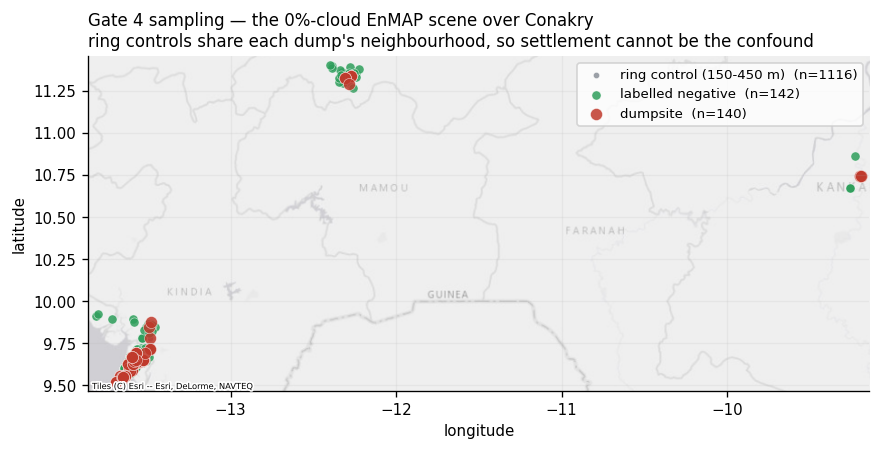

In [16]:
d  = np.load(RUNS / "enmap_spectra" / "spectra.npz", allow_pickle=True)
S, wl, kind = d["spectra"], d["wavelengths"], d["kind"]

# EnMAP L2A returns garbage in the deep water-vapour windows; drop them.
bad = ((wl >= 1340) & (wl <= 1460)) | ((wl >= 1800) & (wl <= 1960))
S, wl = S[:, ~bad], wl[~bad]
dump, ring, neg = S[kind=="dump"], S[kind=="ring_control"], S[kind=="labelled_negative"]
print(f"{len(dump)} dump   {len(ring)} ring control   {len(neg)} labelled negative"
      f"   x {S.shape[1]} usable bands")

# lon/lat are written by script 18 straight from the scene's own CRS — do not
# reconstruct them from the UTM columns here. Hardcoding the zone once already
# put this map 6 degrees east of Conakry (the scene is 32628, not 32629).
spts = pd.read_csv(RUNS / "enmap_spectra" / "points.csv")
sg = gpd.GeoDataFrame(spts, geometry=gpd.points_from_xy(spts.lon, spts.lat),
                      crs="EPSG:4326")

fig, ax = plt.subplots(figsize=(8.4, 7.0))
for k, c, s, lb in (("ring_control", MUTE, 14, "ring control (150-450 m)"),
                    ("labelled_negative", "#2e9e5b", 30, "labelled negative"),
                    ("dump", BAD, 52, "dumpsite")):
    g = sg[sg.kind == k]
    if len(g):
        g.plot(ax=ax, color=c, markersize=s, alpha=.85,
               edgecolor="white", linewidth=.3, label=f"{lb}  (n={len(g)})")
basemap(ax, sg, pad=.05)
ax.legend(frameon=True, fontsize=8, loc="upper right")
ax.set_title("Gate 4 sampling — the 0%-cloud EnMAP scene over Conakry\n"
             "ring controls share each dump's neighbourhood, so settlement "
             "cannot be the confound", loc="left", fontsize=10)
save(fig, "11_map_enmap_sampling"); plt.show()

wrote plasticwaste_tool\runs\figures\05_enmap_mean_spectra.png


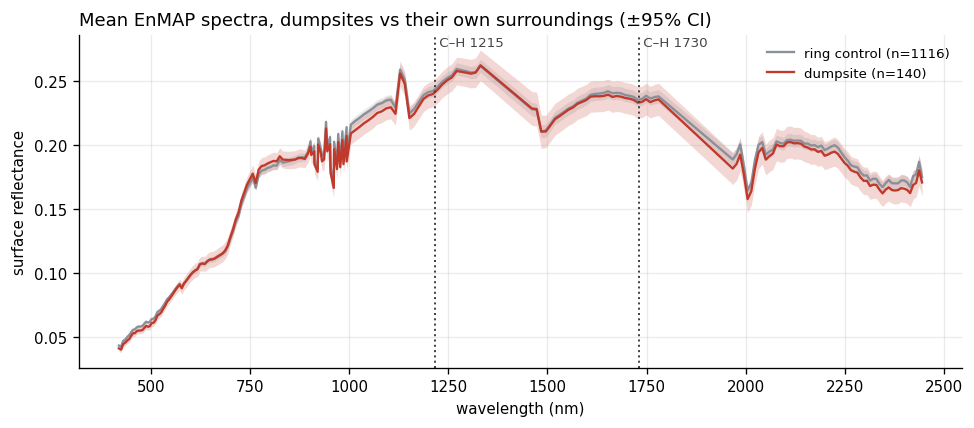

In [17]:
def band(m, c, lab, ax):
    mu = m.mean(0); se = m.std(0)/np.sqrt(len(m))
    ax.plot(wl, mu, color=c, lw=1.4, label=f"{lab} (n={len(m)})")
    ax.fill_between(wl, mu-1.96*se, mu+1.96*se, color=c, alpha=.20, lw=0)

fig, ax = plt.subplots(figsize=(9.5, 3.6))
band(ring, MUTE, "ring control", ax); band(dump, BAD, "dumpsite", ax)
for f in (1215, 1730):
    ax.axvline(f, color="#444", ls=":", lw=1.2)
    ax.text(f, ax.get_ylim()[1]*.97, f" C–H {f}", fontsize=8, color="#444")
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("surface reflectance")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Mean EnMAP spectra, dumpsites vs their own surroundings (±95% CI)", loc="left")
save(fig, "05_enmap_mean_spectra"); plt.show()

wrote plasticwaste_tool\runs\figures\06_enmap_per_band_ap.png


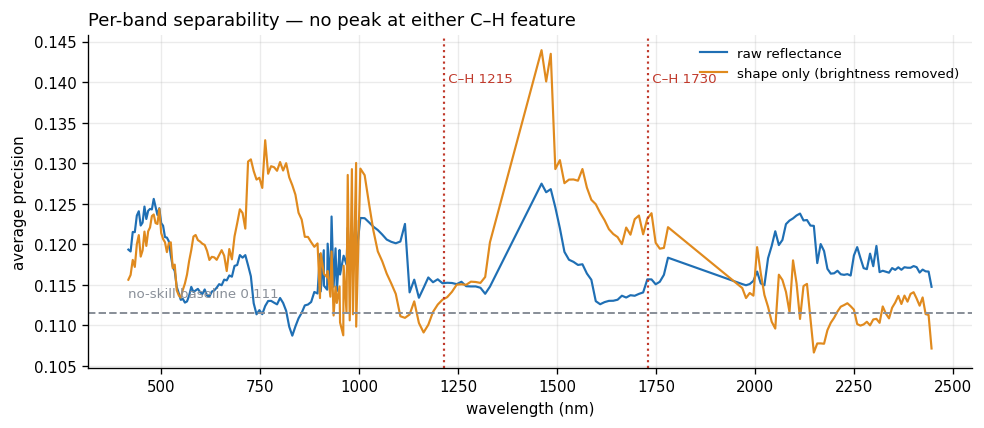

C–H 1215 nm:  raw AP 0.115 (rank 140/218)   shape-only AP 0.113 (rank 163/218)
C–H 1730 nm:  raw AP 0.116 (rank 128/218)   shape-only AP 0.123 (rank 46/218)

best band overall: AP 0.127 at 1461 nm (lift 1.14 over baseline)


In [18]:
from sklearn.metrics import average_precision_score

y = np.r_[np.ones(len(dump)), np.zeros(len(ring))]
X = np.vstack([dump, ring]); base = y.mean()

def per_band(M):
    return np.array([max(average_precision_score(y, M[:, i]),
                         average_precision_score(y, -M[:, i]))
                     for i in range(M.shape[1])])

ap_raw   = per_band(X)
ap_shape = per_band(X / X.mean(1, keepdims=True))   # albedo removed

fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(wl, ap_raw,   color=INK,  lw=1.3, label="raw reflectance")
ax.plot(wl, ap_shape, color=WARN, lw=1.3, label="shape only (brightness removed)")
ax.axhline(base, color=MUTE, ls="--", lw=1.2)
ax.text(wl.min(), base+.002, f"no-skill baseline {base:.3f}", color=MUTE, fontsize=8)
for f in (1215, 1730):
    ax.axvline(f, color=BAD, ls=":", lw=1.3)
    ax.text(f, ax.get_ylim()[1]*.96, f" C–H {f}", fontsize=8, color=BAD)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("average precision")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Per-band separability — no peak at either C–H feature", loc="left")
save(fig, "06_enmap_per_band_ap"); plt.show()

for f in (1215, 1730):
    i = int(np.argmin(abs(wl-f)))
    print(f"C–H {f} nm:  raw AP {ap_raw[i]:.3f} (rank {int((ap_raw>ap_raw[i]).sum())+1}/{len(wl)})"
          f"   shape-only AP {ap_shape[i]:.3f} "
          f"(rank {int((ap_shape>ap_shape[i]).sum())+1}/{len(wl)})")
print(f"\nbest band overall: AP {ap_raw.max():.3f} at {wl[ap_raw.argmax()]:.0f} nm "
      f"(lift {ap_raw.max()/base:.2f} over baseline)")

There is no peak at either diagnostic wavelength. Separability is a broad,
shallow SWIR continuum effect — the signature of *brightness and composition*,
not of a C–H bond.

The remaining possibility is that the information is multivariate rather than
per-band. Below, `20_enmap_separability.py` reports a full-spectrum classifier
with **leave-one-dumpsite-out** blocking (a site appearing in three scenes is
one site, not three), per scene and pooled.

In [19]:
sep = json.loads((RUNS / "enmap_spectra" / "separability.json").read_text())

rows = []
for sc, r in sep["per_scene"].items():
    mv = r.get("multivariate_raw") or {}
    rows.append({"scene": sc.split("-")[-1][:22], "sites": r["n_distinct_sites"],
                 "dump spectra": r["n_dump_spectra"], "baseline": r["baseline_ap"],
                 "best band AP": r["best_raw_ap"], "lift": r["best_raw_lift"],
                 "multivar OOF AP": mv.get("oof_ap"), "multivar lift": mv.get("lift")})
per = pd.DataFrame(rows).set_index("scene").round(3)
display(per)
print("Scenes carrying only ONE distinct site cannot be cross-validated "
      "(multivar = NaN):\n  with a single site, leave-one-site-out has no "
      "training data left. Their high\n  single-band lift is one site against "
      "its own ring and does not generalise.")

,sites,dump spectra,baseline,best band AP,lift,multivar OOF AP,multivar lift
scene,,,,,,,
DT0000055956_20231222T,19,35,0.111,0.259,2.326,0.222,1.996
DT0000055957_20231225T,19,38,0.113,0.188,1.667,0.153,1.358
DT0000055958_20231229T,18,37,0.110,0.198,1.795,0.168,1.520
DT0000060721_20240209T,1,12,0.111,0.410,3.691,NaN,NaN
DT0000069186_20240415T,3,6,0.111,0.241,2.165,0.084,0.752
DT0000113031_20250125T,1,12,0.111,0.313,2.818,NaN,NaN


Scenes carrying only ONE distinct site cannot be cross-validated (multivar = NaN):
  with a single site, leave-one-site-out has no training data left. Their high
  single-band lift is one site against its own ring and does not generalise.


In [20]:
p = sep["pooled"]
print(f"POOLED — {p['n_spectra']} spectra, {p['n_dump_spectra']} from dumps, "
      f"{p['n_distinct_sites']} DISTINCT SITES")
print(f"  baseline AP                      {p['baseline_ap']:.3f}")
print(f"  best single band                 {p['best_raw_ap']:.3f} "
      f"at {p['best_raw_nm']:.0f} nm   lift {p['best_raw_lift']:.2f}")
b = p.get("best_band_minus_baseline")
if b:
    print(f"    vs baseline (cluster boot)     dAP={b['delta_ap']:+.3f} "
          f"[{b['ci95'][0]:+.3f}, {b['ci95'][1]:+.3f}]  "
          f"{'significant' if b['excludes_zero'] else 'not significant'}")
for nm, key in (("raw", "multivariate_raw"), ("brightness removed", "multivariate_shape")):
    mv = p[key]
    print(f"  multivariate, {nm:<18} OOF AP {mv['oof_ap']:.3f}   lift {mv['lift']:.2f}")

print(f"\nC-H features — rank among {p['ch_features']['1215nm']['n_bands']} bands:")
for f, v in p["ch_features"].items():
    print(f"  {f:>8}   raw AP {v['raw_ap']:.3f}  rank {v['raw_rank']:>3}"
          f"   |  brightness removed: AP {v['shape_ap']:.3f}  rank {v['shape_rank']:>3}")

print("\nRead this carefully — it is the crux of the whole module:")
print("  * Weak separability DOES exist (multivariate lift ~1.9). Dumps are")
print("    bare and disturbed, so of course they differ a little from their")
print("    surroundings.")
print("  * But BOTH C-H features rank MID-PACK among 218 bands. If plastic")
print("    were driving the signal they would be at the top. They are not.")
print("  * Removing brightness cuts the multivariate lift from ~1.95 to ~1.41,")
print("    so much of what little signal exists is albedo.")
print("\n  Separability without a C-H signature is bare ground -- the same")
print("  answer gates 2 and 3 reached by two other routes.")

POOLED — 1256 spectra, 140 from dumps, 30 DISTINCT SITES
  baseline AP                      0.111
  best single band                 0.127 at 1461 nm   lift 1.14
    vs baseline (cluster boot)     dAP=+0.030 [+0.007, +0.100]  significant
  multivariate, raw                OOF AP 0.218   lift 1.95
  multivariate, brightness removed OOF AP 0.157   lift 1.41

C-H features — rank among 218 bands:
    1215nm   raw AP 0.115  rank 140   |  brightness removed: AP 0.113  rank 163
    1730nm   raw AP 0.116  rank 128   |  brightness removed: AP 0.123  rank  46

Read this carefully — it is the crux of the whole module:
  * Weak separability DOES exist (multivariate lift ~1.9). Dumps are
    bare and disturbed, so of course they differ a little from their
    surroundings.
  * But BOTH C-H features rank MID-PACK among 218 bands. If plastic
    were driving the signal they would be at the top. They are not.
  * Removing brightness cuts the multivariate lift from ~1.95 to ~1.41,
    so much of what l

## 7. Verdict

**Estimating the plastic FRACTION of a dumpsite is not achievable from
satellite for Guinea.** Note the scope carefully — detecting plastic
accumulation *is* achievable and is already delivered (see the scope box at the
top). What fails is ranking one detected dump against another by plastic
content. Four independent lines of evidence agree:

1. **Sentinel-2 cannot sample the physics.** Neither C–H feature falls in a band.
2. **Every index tested is a bare-ground detector.** NDVI — with no plastic
   sensitivity at all — matches or beats PMLI, PGI, RPGI, Vi and the FDI family.
   Three different formula families converge on the same non-specific signal.
3. **Dumps are sub-pixel everywhere.** Median 14 m: 0.22 of an EnMAP pixel,
   0.05 of an EMIT pixel. No sensor resolves one.
4. **EnMAP shows no C–H signature.** Across six 0%-cloud scenes, four regions
   and three years (30 distinct sites), both diagnostic features rank
   mid-pack among 218 bands (1215 nm rank 140, 1730 nm rank 128). Weak
   separability exists, but removing brightness cuts it by a third — it is
   albedo, not absorption.

### What is honest to claim, and what is not

| claim | status |
|---|---|
| "We map floating-debris accumulation on water from Sentinel-2" | **true, delivered** — FDI rule + MARIDA classifier; MARIDA precision 0.92 on unseen tiles, Conakry photo review 37% |
| "We map waste accumulation sites on land from satellite" | **true, delivered** — Module 1 |
| "Usable hyperspectral data exists over ~all Guinean dumpsites" | **true** (gate 1) |
| "Dumpsites in Guinea are ~14 m across" | **true, newly measured** |
| "Sentinel-2 indices detect dumpsites" | true, but via bare ground — Module 1 does it better with RGB |
| "We can estimate plastic concentration" | **not supported** |
| "We can rank plastic-heavy vs organic dumps" | **not supported** |

### Why, in one line

The target is ~14 m, the finest SWIR pixel available is 20 m, and the plastic
fraction *within* that sub-pixel target is the unknown we were asked to
measure. The signal is below the floor of every instrument in orbit that can
see the relevant physics.

This is a limit of the field, not of this implementation. No published study
estimates plastic fraction within a terrestrial waste site from orbit; the best
terrestrial work detects sites and says so explicitly.

### What would change the answer

* **Ground truth.** Nothing here is validated against real plastic fractions,
  because none exist for Guinea. Even a positive result would have been
  unvalidatable.
* **Sub-metre airborne or UAV hyperspectral.** Removes the sub-pixel problem
  entirely. This is what the published landfill successes (PRISMA over Ghazipur
  and Okhla) actually had going for them — those landfills are hundreds of
  metres across.
* **More EnMAP scenes.** 21 are available at ≤10% cloud; this used one (n=38
  dumps). A larger sample would tighten the confidence intervals, but the
  sub-pixel mechanism is not something more scenes can fix.

## 7b. What *is* deliverable: waste mobilisation and leakage risk

Characterisation asks what a dumpsite is **made of** — which needs a per-site
material measurement no satellite can provide. Mobilisation asks where waste
**goes**, which is a function of terrain, rainfall and drainage, all directly
observable. It sidesteps the unknown rather than depending on it.

This is the concept note's own **Waste Flow and Mobilization Modeling**
activity:

> "By integrating the hotspot maps with data on rainfall, river networks
> (hydrology), and topography (DEMs), we can simulate how and when plastic from
> dumpsites mobilizes during the rainy season … predict which river basins are
> at highest risk, identify optimal locations for river-based traps, and
> prioritize interventions before plastic reaches the ocean."

### Literature basis

Two published model families, reproduced here in reduced form:

* **Meijer, van Emmerik, van der Ent, Schmidt & Lebreton (2021)**, *"More than
  1000 rivers account for 80% of global riverine plastic emissions into the
  ocean"*, **Science Advances 7(18):eaaz5803** — a probabilistic model
  combining waste, land use, wind, precipitation and river networks. Its two
  dominant geometric terms are **distance to the river network** and
  **distance to the basin outlet**.
* **The Plastic Pathfinder** (Mellink, van Emmerik et al.) — waste is mobilised
  when **driving forces (surface runoff and wind) overcome terrain friction,
  a function of slope and land-use type**. Urban surfaces mobilise readily;
  forest resists.

A comparable GIS/remote-sensing leakage mapping approach for a tropical
developing basin is given for the Lower Mekong in *Sustainability* 14(13):7879.

### What is computed, from data already in hand

    risk = mass × P(mobilise) × P(reach watercourse) × P(reach ocean)

| term | source | role |
|---|---|---|
| wet-season rainfall | CHIRPS daily, May–Oct | runoff driver |
| terrain slope | SRTM 30 m | gravitational driver |
| land-cover friction | ESA WorldCover | resisting force (Pathfinder) |
| distance to watercourse | HydroSHEDS flow accumulation | Meijer term 1 |
| distance to sea | ETOPO1 bathymetry | Meijer term 2 (outlet) |
| waste mass proxy | measured size class (§5) | source strength |

### On the plastic fraction

The unknown plastic fraction does not make the model unusable: Meijer et al. do
not measure plastic fraction from imagery either. Their MPW input is computed from
*population density × per-capita waste generation × mismanaged fraction ×
**the proportion of plastic in solid waste***, the last taken from national
waste-composition statistics (the lineage runs Jambeck et al. 2015 → Lebreton &
Andrady 2019 → Meijer et al. 2021).

So a plastic-weighted mass term **is** obtainable for Guinea — from a national
waste characterisation figure (World Bank *What a Waste 2.0*, or ANASP), not
from satellite. That is a data-sourcing task, not a remote-sensing limitation.
Until such a figure is in hand the mass term below is **waste**, not plastic.

### Two limits that must travel with the output

1. **The mass term is waste, not plastic** — see above. Resolvable with a
   national waste-composition statistic.
2. **No Guinean calibration data.** Meijer et al. calibrated against 2017–2020
   field observations of riverine plastic flux; no equivalent exists here.

### Independent validation against observed flooding — and it does not pass

Calibrating an emission model needs observed plastic flux, which Guinea does
not have. But the **mobilisation mechanism itself** can be checked against
independent observation: the **Global Flood Database** (Tellman et al. 2021,
*Nature* 596:80–86) holds MODIS-derived flood extents, **8 events over Guinea**,
all rain-driven. A dumpsite that has been inundated has demonstrably had water
move through it.

This is a concordance test of the hydrological half, using data entirely
independent of the terrain, rainfall and drainage terms the score is built
from. Every component is reported separately, so an inverted term cannot hide
inside the product.

In [21]:
# self-contained: this cell sits above the one that loads `msum`
_ms = json.loads((RUNS / "mobilisation" / "mobilisation_summary.json").read_text())
val = _ms.get("flood_validation", {})
if val.get("status") == "ok":
    print(f"sites inundated in an observed flood: {val['n_flooded']}/{val['n_sites']}"
          f"  ({val['prevalence']:.0%})")
    print(f"flooded by region: {val['flooded_by_region']}\n")
    rows = []
    for c, v in val["components"].items():
        rows.append({"component": c, "AUC": round(v["auc"], 3),
                     "AP": round(v["ap"], 3), "lift": round(v["lift"], 2),
                     "p": round(v["p"], 3),
                     "verdict": ("predicts flooding" if v["auc"] > 0.65 else
                                 "INVERSE" if v["auc"] < 0.35 else "no signal")})
    display(pd.DataFrame(rows).set_index("component"))

sites inundated in an observed flood: 13/111  (12%)
flooded by region: {'Kankan': 11, 'Conakry': 2}



,AUC,AP,lift,p,verdict
component,,,,,
mobilisation_risk,0.771,0.424,3.62,0.001,predicts flooding
ocean_leakage_risk,0.245,0.094,0.80,0.999,INVERSE
p_mobilise,0.725,0.252,2.16,0.004,predicts flooding
p_washoff,0.247,0.093,0.80,0.998,INVERSE
p_inundation,0.766,0.404,3.45,0.001,predicts flooding
p_to_river,0.750,0.332,2.84,0.002,predicts flooding
p_to_ocean,0.203,0.138,1.17,1.000,INVERSE
mass_proxy,0.549,0.129,1.10,0.207,no signal


### How to read this: two mobilisation pathways

Waste can enter a watercourse two physically distinct ways, with different drivers:

| pathway | driver | data |
|---|---|---|
| **wash-off** — rain falls *on* the site, runoff carries waste downslope | local rainfall, slope, land-use friction | CHIRPS, SRTM, WorldCover |
| **inundation** — the river rises *over* the site | upstream catchment discharge | HydroSHEDS flow accumulation |

They are combined as a **union** — either mechanism suffices — not a product, which would wrongly require
both. Meijer et al. use river discharge for the same reason. Wash-off alone does not predict flooding
(ROC-AUC 0.469): 11 of the 13 flooded sites are in **Kankan, on the Niger/Milo floodplain**, where local
wet-season rainfall (1278 mm) is *lower* than at coastal Conakry (2961 mm). Those sites are inundated by
upstream discharge, not by the rain falling on them.

| component | ROC-AUC | p |
|---|---|---|
| **`mobilisation_risk`** | **0.771** | 0.001 |
| `p_mobilise` | 0.725 | 0.004 |
| `p_inundation` | 0.766 | 0.001 |
| `p_to_river` | 0.750 | 0.002 |

**No weight was tuned against the 13 flooded sites.** The two-pathway structure is taken from the source
model, not fitted to the validation set.

### Two components are inverted, and both should be

* **`p_washoff` (0.247)** — the *local-rain* pathway; the flood data only exercises the *riverine* one.
  There is no observational dataset for "waste washed off a site by local rain", so that pathway is
  **untested**, not disproven.
* **`p_to_ocean` (0.203)** — correctly inverted: those Kankan sites are 495 km from the Atlantic. It
  answers a different question from "did this site flood".

### Deployment status of the two scores

| layer | validation | status |
|---|---|---|
| **`mobilisation_risk`** — does waste enter a watercourse? | **AUC 0.771, AP 0.424 vs 0.117 baseline, p = 0.001** | **shippable** |
| `ocean_leakage_risk` — does it reach the Atlantic? | not validatable against flood data (different question) | plausible on Meijer's structure, **unvalidated** |

They rank **differently**, and that is the point rather than a defect.

In [22]:
mob2 = pd.read_csv(RUNS / "mobilisation" / "mobilisation_risk.csv")

reg = (mob2.groupby("region")[["mobilisation_risk", "ocean_leakage_risk"]]
       .mean().sort_values("mobilisation_risk", ascending=False))
display(reg.round(1))

f_m = mob2[mob2.flood_ever == 1]["mobilisation_risk"].mean()
u_m = mob2[mob2.flood_ever == 0]["mobilisation_risk"].mean()
print(f"mean mobilisation_risk — observed-flooded {f_m:.1f} vs unflooded {u_m:.1f}\n")

print("The two scores answer different questions and rank differently:")
print("  mobilisation (does waste reach a watercourse?)  -> riverine sites:")
print("     Nzerekore, Kankan, Kindia lead")
print("  ocean leakage (does it reach the Atlantic?)     -> coastal sites:")
print("     Conakry leads")
print("\nFor siting a river trap or a clean-up, mobilisation is the operational")
print("layer. For marine-plastic accounting, ocean leakage is — but only the")
print("first of the two carries validation evidence.")

,mobilisation_risk,ocean_leakage_risk
region,,
Nzerekore,53.3,13.9
Kankan,39.2,1.8
Kindia,33.4,31.7
Faranah,24.9,4.1
Conakry,15.8,18.8
Mamou,15.1,5.9
Boke,11.6,13.2
Labe,4.5,1.2


mean mobilisation_risk — observed-flooded 44.9 vs unflooded 18.1

The two scores answer different questions and rank differently:
  mobilisation (does waste reach a watercourse?)  -> riverine sites:
     Nzerekore, Kankan, Kindia lead
  ocean leakage (does it reach the Atlantic?)     -> coastal sites:
     Conakry leads

For siting a river trap or a clean-up, mobilisation is the operational
layer. For marine-plastic accounting, ocean leakage is — but only the
first of the two carries validation evidence.


wrote plasticwaste_tool\runs\figures\14_map_mobilisation_vs_ocean.png


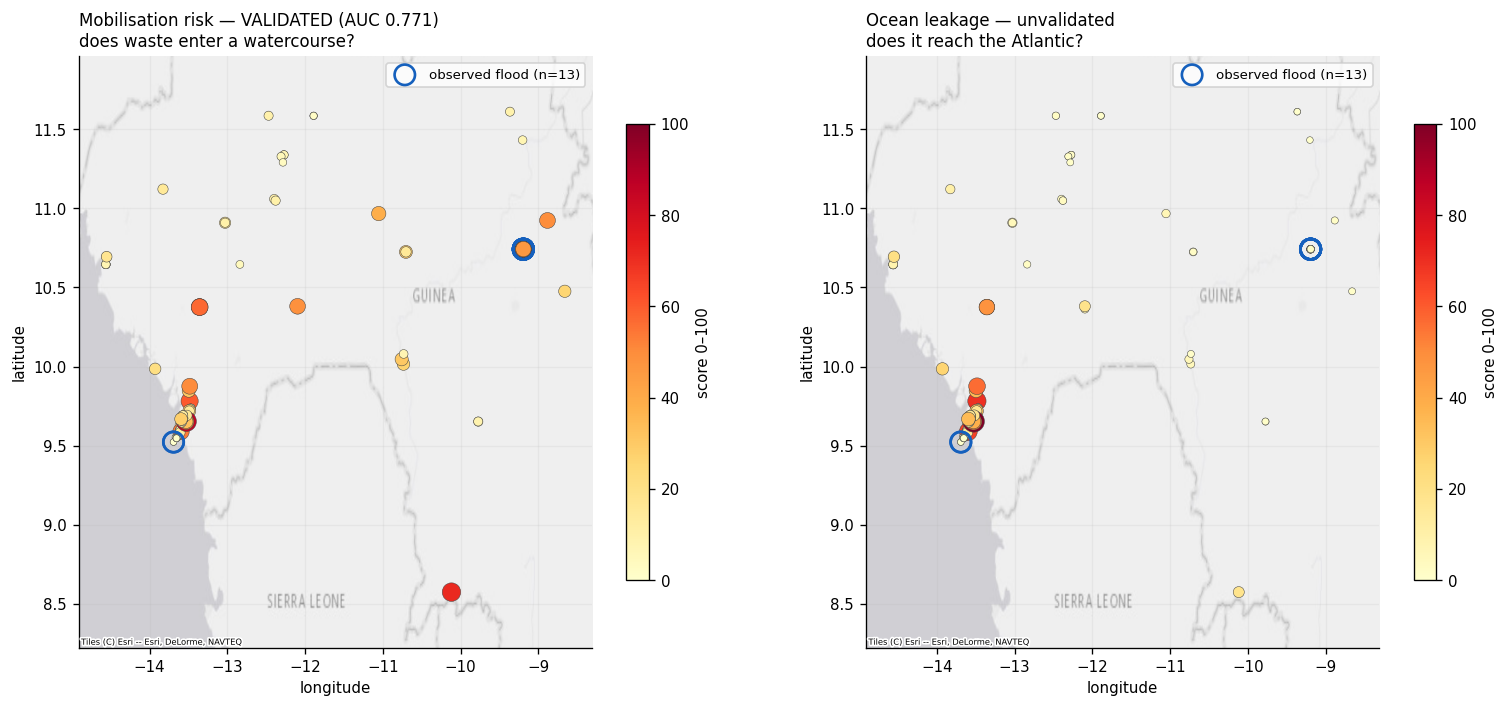

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14.6, 6.4))
fig.subplots_adjust(wspace=.38)
gm = gpd.GeoDataFrame(mob2, geometry=gpd.points_from_xy(mob2.lon, mob2.lat),
                      crs="EPSG:4326")
for ax, col, ttl in (
        (axes[0], "mobilisation_risk",
         "Mobilisation risk — VALIDATED (AUC 0.771)\ndoes waste enter a watercourse?"),
        (axes[1], "ocean_leakage_risk",
         "Ocean leakage — unvalidated\ndoes it reach the Atlantic?")):
    sc = ax.scatter(gm.geometry.x, gm.geometry.y, c=gm[col], cmap="YlOrRd",
                    s=16 + gm[col] * 1.5, edgecolor="#444", linewidth=.3,
                    vmin=0, vmax=100, zorder=3)
    fl = gm[gm.flood_ever == 1]
    ax.scatter(fl.geometry.x, fl.geometry.y, facecolor="none", edgecolor="#1560bd",
               s=150, linewidth=1.6, zorder=4, label="observed flood (n=13)")
    basemap(ax, gm)
    ax.legend(frameon=True, fontsize=8, loc="upper right")
    ax.set_title(ttl, loc="left", fontsize=10)
    plt.colorbar(sc, ax=ax, fraction=.040, pad=.06, label="score 0–100")
save(fig, "14_map_mobilisation_vs_ocean"); plt.show()

In [24]:
mob = pd.read_csv(RUNS / "mobilisation" / "mobilisation_risk.csv")
msum = json.loads((RUNS / "mobilisation" / "mobilisation_summary.json").read_text())

print("Input terms across the national sample:")
for col, unit in (("wet_rain_mm", "mm per wet season"), ("slope_deg", "degrees"),
                  ("dist_river_m", "m to watercourse"), ("dist_ocean_m", "m to sea")):
    v = mob[col].dropna()
    print(f"  {col:<16} median {v.median():>9.0f}   p10 {v.quantile(.1):>9.0f}"
          f"   p90 {v.quantile(.9):>9.0f}   {unit}")

display(mob["risk_class"].value_counts()
        .reindex(["very high", "high", "moderate", "low"]).to_frame("sites"))

top = mob.nsmallest(10, "risk_rank")[
    ["risk_rank", "point_id", "region", "risk_score", "size_class",
     "wet_rain_mm", "dist_river_m", "dist_ocean_m"]]
display(top.set_index("risk_rank").round(1))

Input terms across the national sample:
  wet_rain_mm      median      2128   p10      1238   p90      3335   mm per wet season
  slope_deg        median         3   p10         1   p90         5   degrees
  dist_river_m     median      2148   p10       453   p90      5434   m to watercourse
  dist_ocean_m     median     12143   p10      1275   p90    494950   m to sea


,sites
risk_class,
very high,5
high,20
moderate,32
low,54


,point_id,region,risk_score,size_class,wet_rain_mm,dist_river_m,dist_ocean_m
risk_rank,,,,,,,
1,nat_cona_0031_p0,Conakry,100.0,large,3334.9,908.4,10867.5
2,nat_kind_0033_p0,Kindia,69.8,medium,3502.0,0.0,12142.7
3,nat_cona_0000_p0,Conakry,65.8,large,3641.8,1768.3,3474.4
4,nat_kind_0023_p0,Kindia,56.3,medium,2991.6,642.1,17707.3
5,nat_cona_0031_p3,Conakry,54.4,medium,3334.9,766.3,10600.3
6,nat_cona_0031_p1,Conakry,49.6,medium,3334.9,930.0,10778.4
7,nat_kind_0059_p2,Kindia,47.7,medium,2127.9,266.9,61931.1
8,nat_kind_0059_p0,Kindia,46.6,medium,2127.9,355.9,61949.3
8,nat_kind_0059_p1,Kindia,46.6,medium,2127.9,355.9,61949.3


wrote plasticwaste_tool\runs\figures\13_map_mobilisation_risk.png


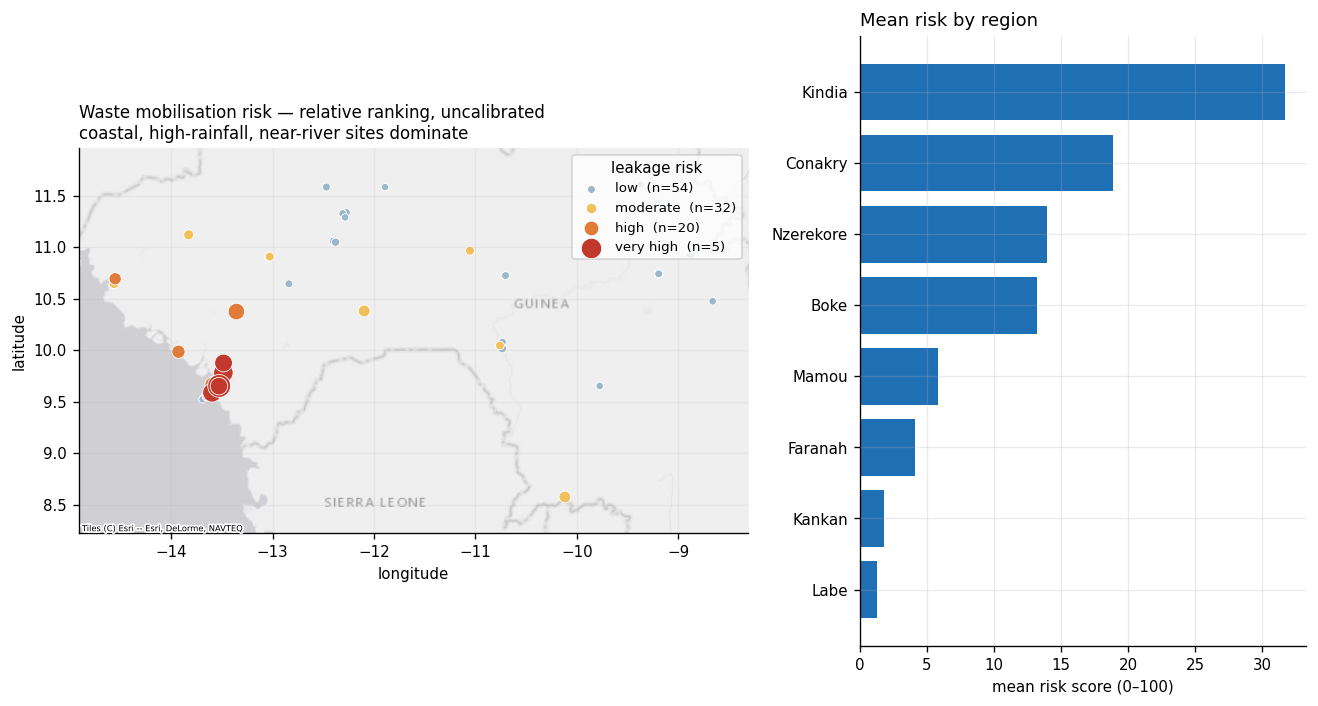

Conakry and Kindia dominate: coastal, close to watercourses, and the
wettest part of the country. Kankan and Faranah score near zero despite
real dumpsites — they sit hundreds of km inland from the sea.

That regional ordering is the product: it says where a river-trap or
a clean-up would most reduce plastic reaching the Atlantic.


In [25]:
gmob = gpd.GeoDataFrame(mob, geometry=gpd.points_from_xy(mob.lon, mob.lat),
                        crs="EPSG:4326")
order = ["low", "moderate", "high", "very high"]
cols = {"low": "#9bb7c9", "moderate": "#f0c05a", "high": "#e07b39",
        "very high": BAD}

fig, (axm, axb) = plt.subplots(1, 2, figsize=(13.2, 6.6),
                               gridspec_kw={"width_ratios": [1.5, 1]})
for k in order:
    g = gmob[gmob.risk_class == k]
    if g.empty:
        continue
    g.plot(ax=axm, color=cols[k], markersize=18 + g.risk_score * 1.7,
           edgecolor="white", linewidth=.5, label=f"{k}  (n={len(g)})")
basemap(axm, gmob)
axm.legend(frameon=True, fontsize=8, loc="upper right", title="leakage risk")
axm.set_title("Waste mobilisation risk — relative ranking, uncalibrated\n"
              "coastal, high-rainfall, near-river sites dominate",
              loc="left", fontsize=10)

reg = (mob.groupby("region")["risk_score"].mean().sort_values())
axb.barh(reg.index, reg.values, color=INK)
axb.set_xlabel("mean risk score (0–100)")
axb.set_title("Mean risk by region", loc="left")
save(fig, "13_map_mobilisation_risk"); plt.show()

print("Conakry and Kindia dominate: coastal, close to watercourses, and the")
print("wettest part of the country. Kankan and Faranah score near zero despite")
print("real dumpsites — they sit hundreds of km inland from the sea.")
print("\nThat regional ordering is the product: it says where a river-trap or")
print("a clean-up would most reduce plastic reaching the Atlantic.")

## 8. What this module delivers to the platform

Checked against the Hub SRS (`docs/SRS_GuineaDigitalHub_v2.docx`,
GEDH-FR-0501 to 0507) and against §13 of `dumpsite_detection_workflow.ipynb`,
which already mapped the six plastic UI layers to their sources.

**The headline consequence is a scope change, and it needs to reach the
programme rather than sit in a notebook.** Module 1's §13 records
`material_flags` and `toxicity_flag` as *"present but `None`, pending the
plastic-characterisation component"*. **This is that component, and it cannot
fill them.** Those fields are not pending — they are out of reach of satellite
data and must be reassigned to the Collector app.

### 8.1 Against the SRS layer table

| UI layer | SRS | this module's effect |
|---|---|---|
| Open dumpsites | FR-0503 | **adds** a measured `size_class` and a `waterside_flag` |
| River plastic index | FR-0503 | **adds a link** — riverside dumps are its land-side source |
| Coastal risk areas | FR-0503 | **adds a link** — coastal dumps likewise |
| Waste collection points | FR-0505/6 | unaffected (Collector PWA) |
| Recycling facilities | FR-0504 | unaffected (partner registry) |
| Urban waste density | not in SRS | **do not define it as plastic density** — see 8.4 |

### 8.2 FR-0504 — `material_flags` / `toxicity_flag` must be reassigned

FR-0504 requires each popup to carry material distribution and a toxicity flag,
for the plastic-brick initiative's PVC screening. Gates 2–4 establish that no
orbital sensor can supply either: the diagnostic physics is unsampled by
Sentinel-2, and at ~14 m the target is sub-pixel for every instrument that
*can* sample it.

The UI can still be built against the final schema shape — the fields stay.
What changes is **who fills them**: the Collector app's ground-level material
classifier, which is exactly what the `detect-waste` dataset family
(TACO, UAVVaste, TrashNet …) is suited to. Those datasets were previously set
aside as "wrong module"; they are now the *only* route to FR-0504.

Until the Collector app lands, the honest popup text is
*"material composition requires ground survey — not yet available"*, not a
blank field implying the data is merely late.

### 8.3 FR-0503 — the "concentration level" colour ramp

FR-0503 asks for colour-coding by concentration level. There is no plastic
concentration measure and there will not be one. Module 1 §13 proposed the
**confidence tier** as the ramp; this module adds a second, better-grounded
option: **measured size class**, since size is a real physical property of the
site rather than a property of the model's belief about it.

Recommended: ramp by size class, with confidence tier shown separately as
transparency or a border. That avoids the trap of a map where colour encodes
"how sure the model is" while reading to a user as "how bad the dump is".

### 8.4 "Urban waste density" — definable, but not as plastic

Not in the SRS, and §13 notes it would have to be defined. It should **not** be
defined as plastic density. A defensible definition using only what exists:
dumpsite `area_ha` summed per administrative unit, normalised by settled area
from GHSL SMOD — i.e. *dumpsite burden*, not material composition.

### 8.5 Do NOT deploy

* **Any "plastic concentration" or "plastic-heaviness" layer.** Falsified in
  gates 2–4. Shipping a bare-ground proxy relabelled as plastic is the single
  worst outcome available here — it would look plausible on a map, colour a
  ramp convincingly, and be wrong.
* **FDI extended to land.** The pipeline yields zero land pixels *by design*;
  removing the water constraint reintroduces the warehouse-roof failure it was
  added to fix.

### 8.6 Deploy — two real additions

**`size_class`** — from §5's measured distribution. `area_ha` is already
required by FR-0504 and currently derives from cell counts; a measured size
distribution makes it defensible and turns "a dump is here" into "a dump of
roughly this size is here".

**`waterside_flag`** — gate 3 found 19 of 111 dump points on WorldCover
water/wetland/mangrove classes (~9% of *sites* once clustering is accounted
for). This is the land-to-ocean plastic pathway, and it connects the
**Open dumpsites** layer to the **River plastic index** and **Coastal risk
areas** layers that already exist. No new model.

### 8.7 Proposed layer registry entries

In [26]:
layers = pd.DataFrame([
    dict(field_or_layer="Open dumpsites (polygons)", srs="FR-0503", status="SHIP",
         owner="Module 1 cascade",
         note="exists; this module adds size_class + waterside_flag"),
    dict(field_or_layer="   - size_class", srs="FR-0503/0504", status="SHIP (new)",
         owner="this module §5",
         note="small <10 m / medium 10-20 m / large >20 m; measured, n=46"),
    dict(field_or_layer="   - waterside_flag", srs="FR-0503", status="SHIP (new)",
         owner="WorldCover x dumpsite",
         note="~9% of sites; links dumpsites to the river/coastal FDI layers"),
    dict(field_or_layer="   - mobilisation_risk", srs="concept note / FR-0503",
         status="SHIP (new)", owner="this module §7b",
         note="VALIDATED vs observed floods: AUC 0.771, AP 0.424, p=0.001"),
    dict(field_or_layer="   - ocean_leakage_risk", srs="concept note (optional)",
         status="SHIP w/ caveat", owner="this module §7b",
         note="Meijer structure; NOT validatable against flood data (different question)"),
    dict(field_or_layer="   - area_ha", srs="FR-0504", status="SHIP",
         owner="Module 1",
         note="now defensible — backed by a measured size distribution"),
    dict(field_or_layer="   - material_flags", srs="FR-0504", status="REASSIGN",
         owner="Collector app",
         note="NOT pending this module — satellite cannot fill it"),
    dict(field_or_layer="   - toxicity_flag", srs="FR-0504", status="REASSIGN",
         owner="Collector app",
         note="same; PVC screening needs ground photography"),
    dict(field_or_layer="River plastic index", srs="FR-0503", status="SHIP (exists)",
         owner="FDI, rivers",
         note="unchanged; riverside dumps now flagged as its land-side source"),
    dict(field_or_layer="Coastal risk areas", srs="FR-0503", status="SHIP (exists)",
         owner="FDI, coast",
         note="unchanged; coastal dumps likewise"),
    dict(field_or_layer="plastic_concentration", srs="concept note", status="DO NOT SHIP",
         owner="—",
         note="falsified gates 2-4; unvalidatable even if it had worked"),
    dict(field_or_layer="Urban waste density", srs="not in SRS", status="DEFINE ONLY AS BURDEN",
         owner="—",
         note="area_ha per admin unit / SMOD settled area — never as plastic density"),
])
display(layers.set_index("field_or_layer"))

print("\nUI copy for the plastic section, if it must say something today:")
print('  "AI-detected dumpsite candidates, not field-verified, with estimated')
print('   size and waterside sites flagged for marine-debris monitoring.')
print('   Material composition requires ground survey and is collected via')
print('   the Collector app."')
print("\n(keeps Module 1 §13's 'not field-verified' wording — status is still")
print(" 'unverified' on every polygon, and nothing here changes that)")

,srs,status,owner,note
field_or_layer,,,,
Open dumpsites (polygons),FR-0503,SHIP,Module 1 cascade,exists; this module adds size_class + watersid...
- size_class,FR-0503/0504,SHIP (new),this module §5,small <10 m / medium 10-20 m / large >20 m; me...
- waterside_flag,FR-0503,SHIP (new),WorldCover x dumpsite,~9% of sites; links dumpsites to the river/coa...
- mobilisation_risk,concept note / FR-0503,SHIP (new),this module §7b,"VALIDATED vs observed floods: AUC 0.771, AP 0...."
- ocean_leakage_risk,concept note (optional),SHIP w/ caveat,this module §7b,Meijer structure; NOT validatable against floo...
- area_ha,FR-0504,SHIP,Module 1,now defensible — backed by a measured size dis...
- material_flags,FR-0504,REASSIGN,Collector app,NOT pending this module — satellite cannot fil...
- toxicity_flag,FR-0504,REASSIGN,Collector app,same; PVC screening needs ground photography
River plastic index,FR-0503,SHIP (exists),"FDI, rivers",unchanged; riverside dumps now flagged as its ...



UI copy for the plastic section, if it must say something today:
  "AI-detected dumpsite candidates, not field-verified, with estimated
   size and waterside sites flagged for marine-debris monitoring.
   Material composition requires ground survey and is collected via
   the Collector app."

(keeps Module 1 §13's 'not field-verified' wording — status is still
 'unverified' on every polygon, and nothing here changes that)


### 8.8 Work items, in order

These add fields to the dumpsite layer of `dumpsite_detection_workflow.ipynb`,
whose national scan runs on free Esri imagery as an analyst-only screening layer
(that notebook, Part 3). Its accuracy limits are its own; nothing here changes
them, and the two conclusions stay separate.

1. **Re-scope FR-0504 with the programme.** `material_flags` / `toxicity_flag`
   move from "pending plastic characterisation" to "pending Collector app".
   This is the item with an external dependency, so it should go first.
2. **Wire `size_class`** into the Module 1 output contract — one field, derived
   from §5's measured distribution.
3. **Add `waterside_flag`** by intersecting dumpsite polygons with WorldCover
   80/90/95, and cross-link those sites to the river/coastal FDI layers.
4. **Decide the FR-0503 ramp** — size class as colour, confidence tier as
   transparency (see 8.3).
5. **Write the methodology document** stating the negative result explicitly.
   A documented falsification is a real contribution; a quietly dropped
   deliverable is not.
6. *(optional)* Extend gate 4 to the other 20 EnMAP scenes. Unlikely to change
   the conclusion — the constraint is geometric, not statistical.

### 8.9 What to say to the programme

The concept note asks to *"estimate the plastic concentration, distinguishing
plastic-heavy hotspots from organic dumps"*. That is not achievable from
satellite, for a reason that is physical rather than methodological:

> The diagnostic signal is C–H absorption at 1215 and 1730 nm. Sentinel-2 does
> not sample either wavelength. The sensors that do — EnMAP, EMIT — have 30–60 m
> pixels, and Guinea's dumpsites measure ~14 m. The target is sub-pixel for
> every instrument in orbit that can see the relevant physics, and the plastic
> fraction *within* that sub-pixel target is precisely the quantity requested.

What this work delivers instead: a measured size distribution for Guinean
dumpsites (the first that exists), a waterside-dumping flag that connects the
dumpsite layer to the already-validated marine debris layers, and a documented
falsification that stops the programme spending further budget on an
unreachable target. Composition data remains achievable — through the Collector
app, at ground level, where the same `detect-waste` models that are useless
from orbit work well.